Add your import statements and the database connection statements in the below code block

Database file path = '/course/data/CSE-578/dinofunworld.db'

In [25]:
# your code here
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pandas.plotting import parallel_coordinates
from pandas.plotting import scatter_matrix

db_filename = '/course/data/CSE-578/dinofunworld.db'
conn = sqlite3.connect(db_filename) 
c = conn.cursor()

### **Question 1:**
Create a distance matrix suitable for use in hierarchical clustering of the checkin sequences of the 5 specified visitors.

Your distance function should count the number of dissimilarities in the sequences without considering any other factors.

**Note** 
* The distance matrix should be reported as a dictionary of dictionaries (eg. {1: {2:0, 3:0, 4:0}, 2: {1:0, 3:0, ...}, ...}).
* The order of the output is not important.

In [26]:
### TEST FUNCTION: test_question1
# DO NOT REMOVE OR MODIFY THE ABOVE LINE
# your code here
sql_query = """
SELECT visitorID, sequence
FROM sequences 
WHERE visitorID IN (165316, 1835254, 296394, 404385, 448990);
"""
c.execute(sql_query)
vistors_sequence_data = c.fetchall() 
vistors_sequence_data_df = pd.DataFrame.from_records(vistors_sequence_data, columns=['VisitorID','Sequence'])
vistors_sequence_data_df['Sequence'] = vistors_sequence_data_df["Sequence"].apply(lambda seq: [int(i) for i in seq.split("-")])
distance_matrix = {}
for i, r1 in vistors_sequence_data_df.iterrows():
    v1 = r1['VisitorID']
    s1 = r1['Sequence']
    distance_matrix[v1] = {}
    for j, r2 in vistors_sequence_data_df.iterrows():
        v2 = r2['VisitorID']
        s2 = r2['Sequence']
        if v1 != v2:  
            distance_matrix[v1][v2] = sum(1 for x, y in zip(s1, s2) if x != y)
print(distance_matrix)

{165316: {296394: 318, 404385: 329, 448990: 318, 1835254: 336}, 296394: {165316: 318, 404385: 303, 448990: 0, 1835254: 282}, 404385: {165316: 329, 296394: 303, 448990: 303, 1835254: 298}, 448990: {165316: 318, 296394: 0, 404385: 303, 1835254: 282}, 1835254: {165316: 336, 296394: 282, 404385: 298, 448990: 282}}


### **Question 2:**  
Create and display a Parallel Coordinate Plot displaying the minimum, maximum and average attendance for each ride in the park.

For this question, display a Parallel Coordinate Plot in the notebook and print the data used to create a Parallel Coordinate Plot as a dictionary of dictionaries (eg: {  'Ride1' : {min : 1, max : 3, avg : 2 }, 'Ride2' :{ min : 1, max : 3, avg : 2 } ... })

**Note:** 
* Not all attractions are rides.
* The output should be a dictionary and the order of the output is not important.
* Use the parallel coordinates function from the **pandas library** to generate the graph.
* The Parallel Coordinate plot must have the below mentioned parameters,
    * legend and it should be outside the plot.
    * y-label ('**Attendance**')
    * title named '**Ride Attendance - Minimum, Maximum, Average**'
* The plot must not have the following parameters,
    * do not set figure size
    * do not set font size or font-weight for titles and labels

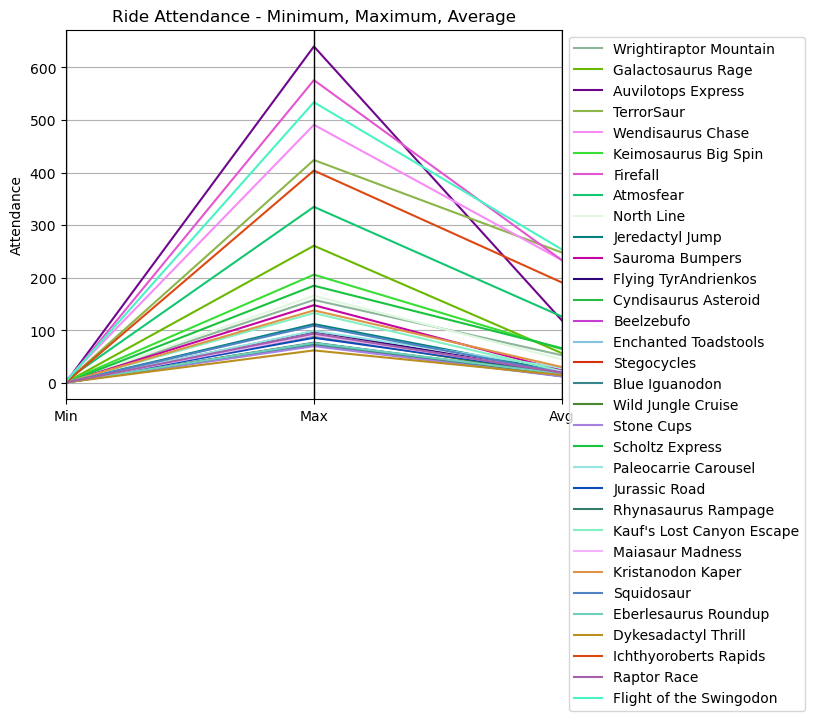

{'Wrightiraptor Mountain': {'min': 1, 'max': 158, 'avg': 52.75}, 'Galactosaurus Rage': {'min': 1, 'max': 261, 'avg': 56.63715277777778}, 'Auvilotops Express': {'min': 1, 'max': 640, 'avg': 118.97916666666667}, 'TerrorSaur': {'min': 2, 'max': 424, 'avg': 248.09375}, 'Wendisaurus Chase': {'min': 5, 'max': 491, 'avg': 233.6875}, 'Keimosaurus Big Spin': {'min': 2, 'max': 206, 'avg': 64.39756944444444}, 'Firefall': {'min': 1, 'max': 576, 'avg': 233.46875}, 'Atmosfear': {'min': 5, 'max': 335, 'avg': 126.359375}, 'North Line': {'min': 1, 'max': 166, 'avg': 45.06944444444444}, 'Jeredactyl Jump': {'min': 1, 'max': 112, 'avg': 21.66840277777778}, 'Sauroma Bumpers': {'min': 1, 'max': 148, 'avg': 23.866319444444443}, 'Flying TyrAndrienkos': {'min': 1, 'max': 98, 'avg': 19.76215277777778}, 'Cyndisaurus Asteroid': {'min': 1, 'max': 72, 'avg': 12.947916666666666}, 'Beelzebufo': {'min': 1, 'max': 93, 'avg': 13.869791666666666}, 'Enchanted Toadstools': {'min': 1, 'max': 77, 'avg': 12.864583333333334}, 

In [27]:
### TEST FUNCTION: test_question2
# DO NOT REMOVE OR MODIFY THE ABOVE LINE
# your code here
sql_query = """
SELECT visitorID, sequence 
FROM sequences;
"""
c.execute(sql_query)
sequence_data = c.fetchall()
sequence_data_df = pd.DataFrame.from_records(sequence_data, columns=['VisitorID', 'Sequence'])
sequence_data_df['Sequence'] = sequence_data_df['Sequence'].apply(lambda s: [int(i) for i in s.split("-")])
second_sql_query = """
SELECT AttractionID, Name 
FROM attraction
WHERE Category LIKE '%Rides%';
"""
c.execute(second_sql_query)
attraction_data = c.fetchall()
attraction_data_df = pd.DataFrame.from_records(attraction_data, columns=["AttractionID", "Name"])
attendance_stats_dict = {}
for i, r in attraction_data_df.iterrows():
    a_id = r["AttractionID"]
    name = r["Name"]
    sequence_data_df['Sequence_List'] = sequence_data_df['Sequence'].apply(lambda s: [1 if i == a_id else 0 for i in s])
    attendance_counts = np.sum(sequence_data_df['Sequence_List'].values.tolist(), axis=0)
    filtered_attendance_counts = attendance_counts[attendance_counts > 0]
    attendance_stats_dict[name] = {
        "min": int(np.min(filtered_attendance_counts)),
        "max": int(np.max(filtered_attendance_counts)),
        "avg": float(np.sum(filtered_attendance_counts) / 576) 
    }
attendance_stats_df = pd.DataFrame.from_dict(attendance_stats_dict, orient="index").reset_index()
attendance_stats_df.columns = ["Ride_Name", "Min", "Max", "Avg"]
parallel_coordinates(attendance_stats_df, "Ride_Name")
plt.title("Ride Attendance - Minimum, Maximum, Average")
plt.ylabel("Attendance")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()
print(attendance_stats_dict)

### **Question 3:**
Create and display a Scatterplot Matrix displaying the minimum, maximum and average attendance for each ride in the park.


**Note:** 
* Print the output values of Question 2 as the same data will be used for Scatterplot.
* The output should be a dictionary (eg: {  'Ride1' : {min : 1, max : 3, avg : 2 }, 'Ride2' :{ min : 1, max : 3, avg : 2 } ... }) and the order of the output is not important.
* This is a different view into the same data as the previous part. Use the scatter plot matrix function from the **pandas library** to generate the graph.
* While you work on these plots, consider the different things that each chart says about the data.
* The Scatterplot must have the below mentioned parameters,
    * title named ' **Scatterplot Matrix - Minimum, Maximum, Average Attendance** '
* The plot must not have the following parameters,
    * legend
    * do not set figure size
    * do not set font size or font-weight for titles and labels

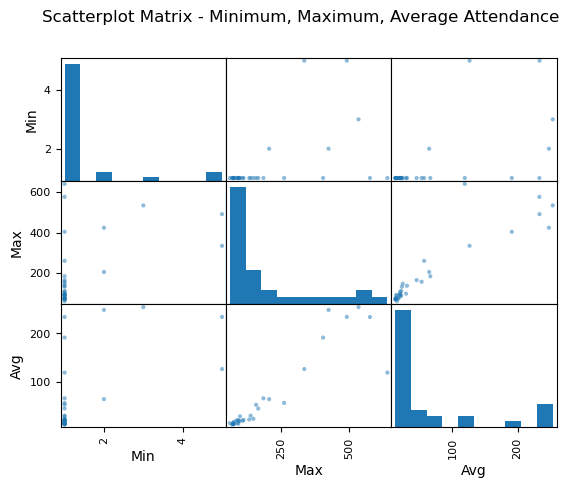

{'Wrightiraptor Mountain': {'min': 1, 'max': 158, 'avg': 52.75}, 'Galactosaurus Rage': {'min': 1, 'max': 261, 'avg': 56.63715277777778}, 'Auvilotops Express': {'min': 1, 'max': 640, 'avg': 118.97916666666667}, 'TerrorSaur': {'min': 2, 'max': 424, 'avg': 248.09375}, 'Wendisaurus Chase': {'min': 5, 'max': 491, 'avg': 233.6875}, 'Keimosaurus Big Spin': {'min': 2, 'max': 206, 'avg': 64.39756944444444}, 'Firefall': {'min': 1, 'max': 576, 'avg': 233.46875}, 'Atmosfear': {'min': 5, 'max': 335, 'avg': 126.359375}, 'North Line': {'min': 1, 'max': 166, 'avg': 45.06944444444444}, 'Jeredactyl Jump': {'min': 1, 'max': 112, 'avg': 21.66840277777778}, 'Sauroma Bumpers': {'min': 1, 'max': 148, 'avg': 23.866319444444443}, 'Flying TyrAndrienkos': {'min': 1, 'max': 98, 'avg': 19.76215277777778}, 'Cyndisaurus Asteroid': {'min': 1, 'max': 72, 'avg': 12.947916666666666}, 'Beelzebufo': {'min': 1, 'max': 93, 'avg': 13.869791666666666}, 'Enchanted Toadstools': {'min': 1, 'max': 77, 'avg': 12.864583333333334}, 

In [28]:
### TEST FUNCTION: test_question3
# DO NOT REMOVE OR MODIFY THE ABOVE LINE
# your code here
sql_query = """
SELECT visitorID, sequence 
FROM sequences;
"""
c.execute(sql_query)
sequence_data = c.fetchall()
sequence_data_df = pd.DataFrame.from_records(sequence_data, columns=['VisitorID', 'Sequence'])
sequence_data_df['Sequence'] = sequence_data_df['Sequence'].apply(lambda s: [int(i) for i in s.split("-")])
second_sql_query = """
SELECT AttractionID, Name 
FROM attraction
WHERE Category LIKE '%Rides%';
"""
c.execute(second_sql_query)
attraction_data = c.fetchall()
attraction_data_df = pd.DataFrame.from_records(attraction_data, columns=["AttractionID", "Name"])
attendance_stats_dict = {}
for i, r in attraction_data_df.iterrows():
    a_id = r["AttractionID"]
    name = r["Name"]
    sequence_data_df['Sequence_List'] = sequence_data_df['Sequence'].apply(lambda s: [1 if i == a_id else 0 for i in s])
    attendance_counts = np.sum(sequence_data_df['Sequence_List'].values.tolist(), axis=0)
    filtered_attendance_counts = attendance_counts[attendance_counts > 0]
    attendance_stats_dict[name] = {
        "min": int(np.min(filtered_attendance_counts)),
        "max": int(np.max(filtered_attendance_counts)),
        "avg": float(np.sum(filtered_attendance_counts) / 576) 
    }
attendance_stats_df = pd.DataFrame.from_dict(attendance_stats_dict, orient="index").reset_index()
attendance_stats_df.columns = ["Ride_Name", "Min", "Max", "Avg"]
scatter_matrix(attendance_stats_df)
plt.suptitle('Scatterplot Matrix - Minimum, Maximum, Average Attendance')
plt.show()
print(attendance_stats_dict)